# FretFly: chroma-based chord classifier baseline (PyTorch)

This notebook is the first PyTorch experiment for the audio path in the roadmap.

It does four things:

1. generates synthetic chord audio for `C`, `G`, `Am`, and `F`
2. turns each clip into a spectrogram and then a chroma (pitch-class) representation
3. trains a small 1D CNN on the chroma features
4. evaluates it with a confusion matrix and an `Unknown` threshold, then saves the weights to `models/`

No camera or microphone recordings are used. The synthetic data is only a sanity check for the pipeline. It does not show that the model can recognize real guitar playing.

## 1. setup

In [1]:
# this cell sets the seed, the audio settings, and the chord vocabulary.
# the vocabulary matches the four chords in the frontend and the backend contracts.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 0
torch.manual_seed(SEED)

SAMPLE_RATE = 22050
DURATION = 1.0
N_FFT = 2048
HOP = 512

CHORDS = ["C", "G", "Am", "F"]
# pitch classes (0 = C, 1 = C#, ... 11 = B) for each chord
CHORD_TONES = {"C": [0, 4, 7], "G": [7, 11, 2], "Am": [9, 0, 4], "F": [5, 9, 0]}

# the notebook runs from training/notebooks, so the project root is two levels up
ROOT = Path.cwd().resolve().parents[1]
MODEL_DIR = ROOT / "models"
print("project root:", ROOT)
print("chords:", CHORDS)

project root: C:\Users\Arshan Rafid\Projects\Guitar_Chord_Vision
chords: ['C', 'G', 'Am', 'F']


## 2. synthetic chord audio

Each chord is a sum of plucked notes. Every note has a few harmonics, a random octave, and a tiny detune. We then add noise at a random level. This is a rough stand-in for a real guitar, so the model has to learn the pitch content rather than one exact waveform.

In [2]:
# builds one synthetic clip for a chord by summing harmonics of each chord tone.
def synth_chord(tones, rng):
    t = np.arange(int(SAMPLE_RATE * DURATION)) / SAMPLE_RATE
    audio = np.zeros_like(t)
    for pc in tones:
        # random octave and tiny detune so the model cannot memorize exact pitches
        midi = 48 + pc + 12 * rng.integers(-1, 2)
        f0 = 440.0 * 2 ** ((midi - 69) / 12) * 2 ** rng.normal(0, 0.003)
        for harmonic in range(1, 5):
            audio += (0.5 ** (harmonic - 1)) * np.sin(2 * np.pi * f0 * harmonic * t)
    # plucked-string decay
    audio = audio * np.exp(-3 * t)
    audio = audio / (np.max(np.abs(audio)) + 1e-8)
    # add noise at a random level
    audio += rng.uniform(0.0, 0.1) * rng.standard_normal(len(t))
    return audio.astype(np.float32)


# builds a labeled set of clips with an even number per chord.
def make_dataset(n_per_class, seed):
    rng = np.random.default_rng(seed)
    waves, labels = [], []
    for index, name in enumerate(CHORDS):
        for _ in range(n_per_class):
            waves.append(synth_chord(CHORD_TONES[name], rng))
            labels.append(index)
    return np.stack(waves), np.array(labels)


train_waves, train_labels = make_dataset(n_per_class=300, seed=SEED)
val_waves, val_labels = make_dataset(n_per_class=100, seed=SEED + 1)
print("train clips:", train_waves.shape, "val clips:", val_waves.shape)

train clips: (1200, 22050) val clips: (400, 22050)


## 3. spectrogram and chroma features

A **spectrogram** shows how much energy each frequency has over time. It is made with a short-time Fourier transform (STFT), which splits the clip into short overlapping windows and measures the frequencies in each one.

**Chroma** folds every frequency into one of 12 pitch classes (C, C#, D, and so on), ignoring the octave. A C major chord has strong C, E, and G energy whether it is played low or high. That makes chroma a good input for chord recognition, and the frame-wise sum gives a compact feature map.

In [3]:
# computes the power spectrogram for a batch of clips with torch.stft.
def power_spectrogram(waves):
    window = torch.hann_window(N_FFT)
    spec = torch.stft(
        torch.from_numpy(waves), n_fft=N_FFT, hop_length=HOP, window=window, return_complex=True
    )
    return spec.abs() ** 2  # (batch, frequency bins, frames)


# folds the spectrogram into 12 pitch classes and normalizes each frame.
def chroma_features(waves):
    power = power_spectrogram(waves)
    freqs = torch.linspace(0, SAMPLE_RATE / 2, power.shape[1])
    # skip very low bins, which carry noise rather than chord pitch
    valid = freqs > 60
    midi = 69 + 12 * torch.log2(freqs.clamp(min=1e-6) / 440.0)
    pitch_class = torch.round(midi).long() % 12

    chroma = torch.zeros(waves.shape[0], 12, power.shape[2])
    for pc in range(12):
        mask = valid & (pitch_class == pc)
        chroma[:, pc, :] = power[:, mask, :].sum(dim=1)
    # normalize each frame so loudness does not affect the features
    return chroma / (chroma.sum(dim=1, keepdim=True) + 1e-8)


train_chroma = chroma_features(train_waves)
val_chroma = chroma_features(val_waves)
print("chroma shape (clips, pitch classes, frames):", tuple(train_chroma.shape))

chroma shape (clips, pitch classes, frames): (1200, 12, 44)


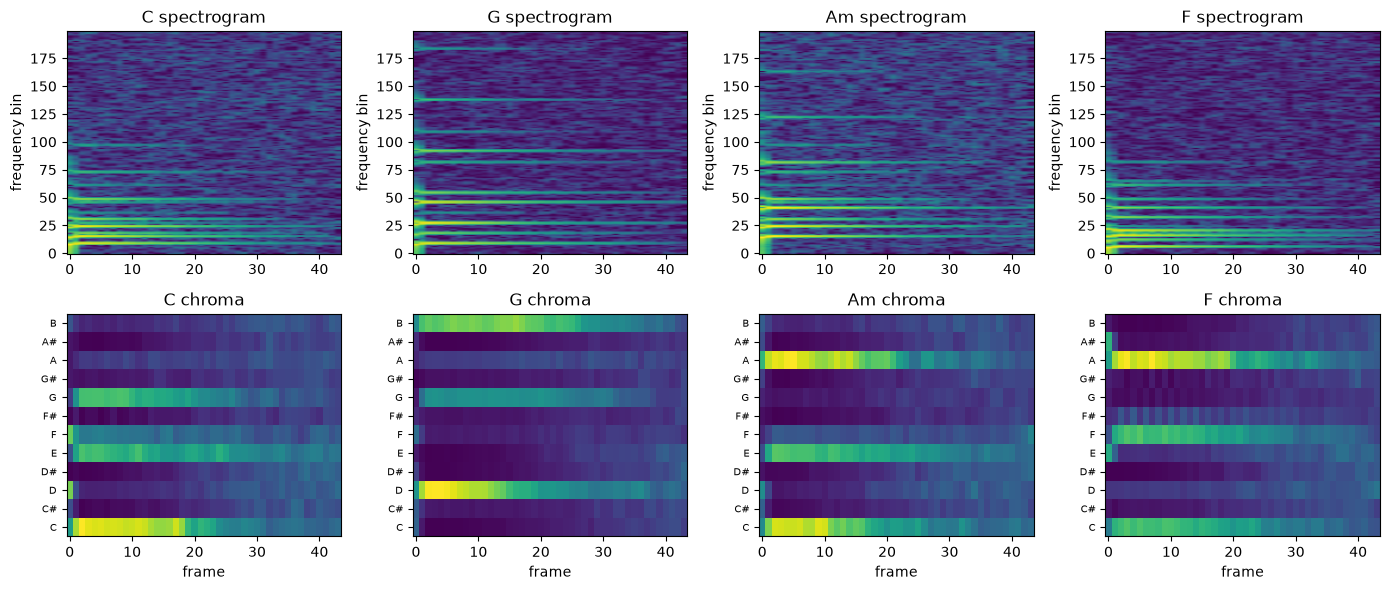

In [4]:
# plots one clip per chord as a spectrogram and a chroma map.
PITCH_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
fig, axes = plt.subplots(2, len(CHORDS), figsize=(14, 6))
for col, name in enumerate(CHORDS):
    clip = int(np.where(train_labels == col)[0][0])
    spec = power_spectrogram(train_waves[clip : clip + 1])[0]
    axes[0, col].imshow(torch.log1p(spec[:200]).numpy(), origin="lower", aspect="auto")
    axes[0, col].set_title(f"{name} spectrogram")
    axes[0, col].set_ylabel("frequency bin")
    axes[1, col].imshow(train_chroma[clip].numpy(), origin="lower", aspect="auto")
    axes[1, col].set_title(f"{name} chroma")
    axes[1, col].set_yticks(range(12))
    axes[1, col].set_yticklabels(PITCH_NAMES, fontsize=7)
    axes[1, col].set_xlabel("frame")
plt.tight_layout()
plt.show()

## 4. dataset and model

In [5]:
# wraps the chroma features in dataloaders for training and validation.
train_loader = DataLoader(TensorDataset(train_chroma, torch.from_numpy(train_labels)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(val_chroma, torch.from_numpy(val_labels)), batch_size=64)


# a small 1d cnn that slides over time and learns which pitch classes stay active together.
class ChordCNN(nn.Module):
    def __init__(self, n_classes=len(CHORDS)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Linear(64, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).squeeze(-1))


model = ChordCNN()
print(sum(p.numel() for p in model.parameters()), "parameters")

12516 parameters


## 5. training loop

In [6]:
# runs one pass over a loader, training when an optimizer is given.
def run_epoch(loader, model, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            count += len(y)
    return total_loss / count, correct / count


EPOCHS = 20
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(train_loader, model, loss_fn, optimizer)
    val_loss, val_acc = run_epoch(val_loader, model, loss_fn)
    for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
        history[key].append(value)
    print(f"epoch {epoch + 1:02d}  train loss {train_loss:.3f} acc {train_acc:.3f}  |  val loss {val_loss:.3f} acc {val_acc:.3f}")

epoch 01  train loss 1.300 acc 0.516  |  val loss 1.085 acc 0.905
epoch 02  train loss 0.746 acc 0.927  |  val loss 0.419 acc 0.938


epoch 03  train loss 0.306 acc 0.928  |  val loss 0.192 acc 0.938
epoch 04  train loss 0.164 acc 0.968  |  val loss 0.110 acc 0.993


epoch 05  train loss 0.100 acc 0.993  |  val loss 0.063 acc 1.000
epoch 06  train loss 0.062 acc 1.000  |  val loss 0.043 acc 1.000


epoch 07  train loss 0.043 acc 1.000  |  val loss 0.027 acc 1.000
epoch 08  train loss 0.029 acc 1.000  |  val loss 0.020 acc 1.000


epoch 09  train loss 0.022 acc 1.000  |  val loss 0.014 acc 1.000
epoch 10  train loss 0.016 acc 1.000  |  val loss 0.011 acc 1.000


epoch 11  train loss 0.012 acc 1.000  |  val loss 0.008 acc 1.000
epoch 12  train loss 0.011 acc 1.000  |  val loss 0.007 acc 1.000


epoch 13  train loss 0.008 acc 1.000  |  val loss 0.006 acc 1.000
epoch 14  train loss 0.007 acc 1.000  |  val loss 0.005 acc 1.000


epoch 15  train loss 0.006 acc 1.000  |  val loss 0.004 acc 1.000
epoch 16  train loss 0.005 acc 1.000  |  val loss 0.003 acc 1.000


epoch 17  train loss 0.005 acc 1.000  |  val loss 0.004 acc 1.000
epoch 18  train loss 0.004 acc 1.000  |  val loss 0.003 acc 1.000


epoch 19  train loss 0.003 acc 1.000  |  val loss 0.003 acc 1.000
epoch 20  train loss 0.003 acc 1.000  |  val loss 0.003 acc 1.000


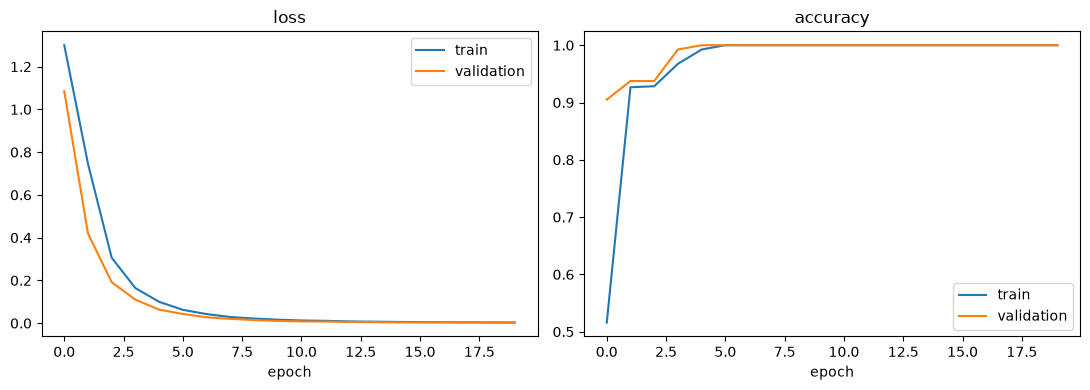

In [7]:
# plots loss and accuracy curves so over-fitting is easy to spot.
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))
ax_loss.plot(history["train_loss"], label="train")
ax_loss.plot(history["val_loss"], label="validation")
ax_loss.set_title("loss")
ax_loss.set_xlabel("epoch")
ax_loss.legend()
ax_acc.plot(history["train_acc"], label="train")
ax_acc.plot(history["val_acc"], label="validation")
ax_acc.set_title("accuracy")
ax_acc.set_xlabel("epoch")
ax_acc.legend()
plt.tight_layout()
plt.show()

## 6. evaluation with an `Unknown` threshold

In [8]:
# returns softmax probabilities for a batch of features.
@torch.no_grad()
def predict_proba(model, features):
    model.eval()
    return torch.softmax(model(features), dim=1).numpy()


probs = predict_proba(model, val_chroma)
predicted = probs.argmax(axis=1)

# builds a confusion matrix with rows as true chords and columns as predictions.
confusion = np.zeros((len(CHORDS), len(CHORDS)), dtype=int)
for true, pred in zip(val_labels, predicted):
    confusion[true, pred] += 1

print("confusion matrix (rows = true, columns = predicted)")
print("        " + "  ".join(f"{name:>4}" for name in CHORDS))
for name, row in zip(CHORDS, confusion):
    print(f"{name:>6}  " + "  ".join(f"{value:>4}" for value in row))
print("overall accuracy:", round((predicted == val_labels).mean(), 3))

confusion matrix (rows = true, columns = predicted)
           C     G    Am     F
     C   100     0     0     0
     G     0   100     0     0
    Am     0     0   100     0
     F     0     0     0   100
overall accuracy: 1.0


In [9]:
# applies the Unknown rule: weak evidence returns Unknown instead of a guess.
CONFIDENCE_THRESHOLD = 0.6

top_prob = probs.max(axis=1)
accepted = top_prob >= CONFIDENCE_THRESHOLD
print(f"threshold {CONFIDENCE_THRESHOLD}: {accepted.mean():.1%} of clips get a chord label")
if accepted.any():
    print("accuracy on accepted clips:", round((predicted[accepted] == val_labels[accepted]).mean(), 3))
print("clips returned as Unknown:", int((~accepted).sum()))

threshold 0.6: 100.0% of clips get a chord label
accuracy on accepted clips: 1.0
clips returned as Unknown: 0


## 7. save the weights

In [10]:
# saves the weights and the feature settings so the backend can rebuild the same pipeline later.
MODEL_DIR.mkdir(exist_ok=True)
checkpoint = {
    "state_dict": model.state_dict(),
    "chords": CHORDS,
    "sample_rate": SAMPLE_RATE,
    "n_fft": N_FFT,
    "hop": HOP,
    "features": "chroma",
    "confidence_threshold": CONFIDENCE_THRESHOLD,
}
path = MODEL_DIR / "chord_cnn_chroma.pt"
torch.save(checkpoint, path)
print("saved", path)

saved C:\Users\Arshan Rafid\Projects\Guitar_Chord_Vision\models\chord_cnn_chroma.pt


## 8. what this shows, and what it does not

**Shows:** the PyTorch pipeline works end to end. Chroma features make the four chords easy to separate, and the `Unknown` rule gives the app a way to stay honest.

**Does not show:** recognition of real guitar audio. Real recordings have room noise, strumming order, muted strings, and different guitars, so the next steps are:

- record a small labeled set of real clips, kept local and out of git
- compare chroma against raw spectrogram features
- check the confidence calibration on real clips
- use the same feature code in the browser or the backend for live inference